In [9]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="v4Fd3aYFnfiPA0hT5dmk")
project = rf.workspace("mojtaba-taj").project("cattle-aerial-finetune")
version = project.version(1)
dataset = version.download("yolov8")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 361.2/361.2 kB 27.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 127.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.8 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Cattle-Aerial-FineTune-1 in yolov8:: 100%|██████████| 48/48 [00:00<00:00, 6456.71it/s]


In [12]:
from ultralytics import YOLO

# Load your existing trained model weights
model = YOLO('best.pt')

# Fine-tune the model using the data.yaml path generated by Roboflow
model.train(data='Cattle-Aerial-FineTune-1/data.yaml', epochs=30, imgsz=640, lr0=0.0001)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=Cattle-Aerial-FineTune-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-3, nbs=64, nms=None, opset=None, optimize=False, o

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7e68ec272510>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [ ]:
from ultralytics import YOLO

# Load the pretrained YOLOv8 small model
model = YOLO('yolov8s.pt')

# Train on your 1.2k cattle dataset
results = model.train(
    data='/content/dataset/data.yaml',
    epochs=30,
    imgsz=640,
    batch=16,
    name='cattle_aerial_model'
)

print("Training finished! Look for your weights in: /content/runs/detect/cattle_aerial_model/weights/best.pt")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, fre

In [13]:
import cv2
from ultralytics import YOLO

# Load your fine-tuned weights
model = YOLO('/content/runs/detect/train-3/weights/best.pt')

# Read a single frame from your video
cap = cv2.VideoCapture('video1.mp4')
ret, frame = cap.read()
if ret:
    results = model.predict(frame, conf=0.1, imgsz=1280, verbose=True)[0]
    print("Raw boxes detected:", results.boxes)
    print("Class names dictionary:", model.names)
cap.release()


0: 736x1280 161 cattles, 56.2ms
Speed: 6.7ms preprocess, 56.2ms inference, 1.9ms postprocess per image at shape (1, 3, 736, 1280)
Raw boxes detected: ultralytics.engine.results.Boxes object with attributes:

cls: tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], device='cuda:0')
conf: tensor([0.8090, 0.7805, 0.7802, 0.7683, 0.7542, 0.7494, 0.7398, 0.7366, 0.7360, 0.7127, 0.6985, 0.6984

In [25]:
from ultralytics import YOLO

# Load your fine-tuned weights
model = YOLO('/content/runs/detect/train-3/weights/best.pt')

# Run inference on the full video and save the output
results = model.predict(
    source='video1.mp4',
    conf=0.25,
    iou=0.25,
    agnostic_nms=True,
    imgsz=640,
    save=True,
    verbose=False
)

print("Inference complete! Check the runs/detect/predict folder for your output video.")

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

Results saved to /content/runs/detect/predict-6
Inference complete! Check the runs/detect/predict folder for your output video.


In [31]:
import cv2
import os
import supervision as sv
from ultralytics import YOLO

# 1. Load your fine-tuned custom weights
MODEL_PATH = '/content/runs/detect/train-3/weights/best.pt'
model = YOLO(MODEL_PATH)

# 2. Setup paths and video parameters
INPUT_VIDEO_PATH = 'video2.mp4'
OUTPUT_VIDEO_PATH = 'output_cleaned_cattle.mp4'

cap = cv2.VideoCapture(INPUT_VIDEO_PATH)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = int(cap.get(cv2.CAP_PROP_FPS)) or 30

# 3. Initialize supervision annotators
box_annotator = sv.BoxAnnotator(thickness=2)
label_annotator = sv.LabelAnnotator(text_scale=0.5, text_thickness=1)

fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter(OUTPUT_VIDEO_PATH, fourcc, fps, (width, height))

print("Processing video stream with NMS filtering on GPU...")
frame_count = 0

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    # Run prediction with balanced confidence
    results = model.predict(frame, conf=0.2, verbose=False)[0]

    # Convert to supervision detections and apply NMS to eliminate overlapping boxes
    detections = sv.Detections.from_ultralytics(results)
    detections = detections.with_nms(threshold=0.2)

    # Generate clean labels
    labels = [f"cattle {confidence:.2f}" for confidence in detections.confidence]

    # Annotate frame with boxes and labels
    annotated_frame = box_annotator.annotate(scene=frame.copy(), detections=detections)
    annotated_frame = label_annotator.annotate(scene=annotated_frame, detections=detections, labels=labels)

    # Optional: Display total active cattle count on the frame
    total_cattle = len(detections)
    cv2.putText(annotated_frame, f"Total Cattle in View: {total_cattle}",
                (30, 50), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 255, 0), 2)

    out.write(annotated_frame)
    frame_count += 1

cap.release()
out.release()
print(f"Done! Processed {frame_count} frames. Video saved to: {OUTPUT_VIDEO_PATH}")

Processing video stream with NMS filtering on GPU...
Done! Processed 319 frames. Video saved to: output_cleaned_cattle.mp4


In [32]:
from google.colab import files
files.download('output_cleaned_cattle.mp4')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
from pathlib import Path

# Search the entire /content directory for any data.yaml file
yaml_files = list(Path('/content').glob('**/data.yaml'))
print("Found data.yaml files:", yaml_files)


Found data.yaml files: [PosixPath('/content/Cattle-Aerial-FineTune-1/data.yaml')]


=== Fine-Tuned Model Validation Metrics ===
mAP50: 0.7167
mAP50-95: 0.2744
Precision: 0.7069
Recall: 0.6598

--- confusion_matrix.png ---


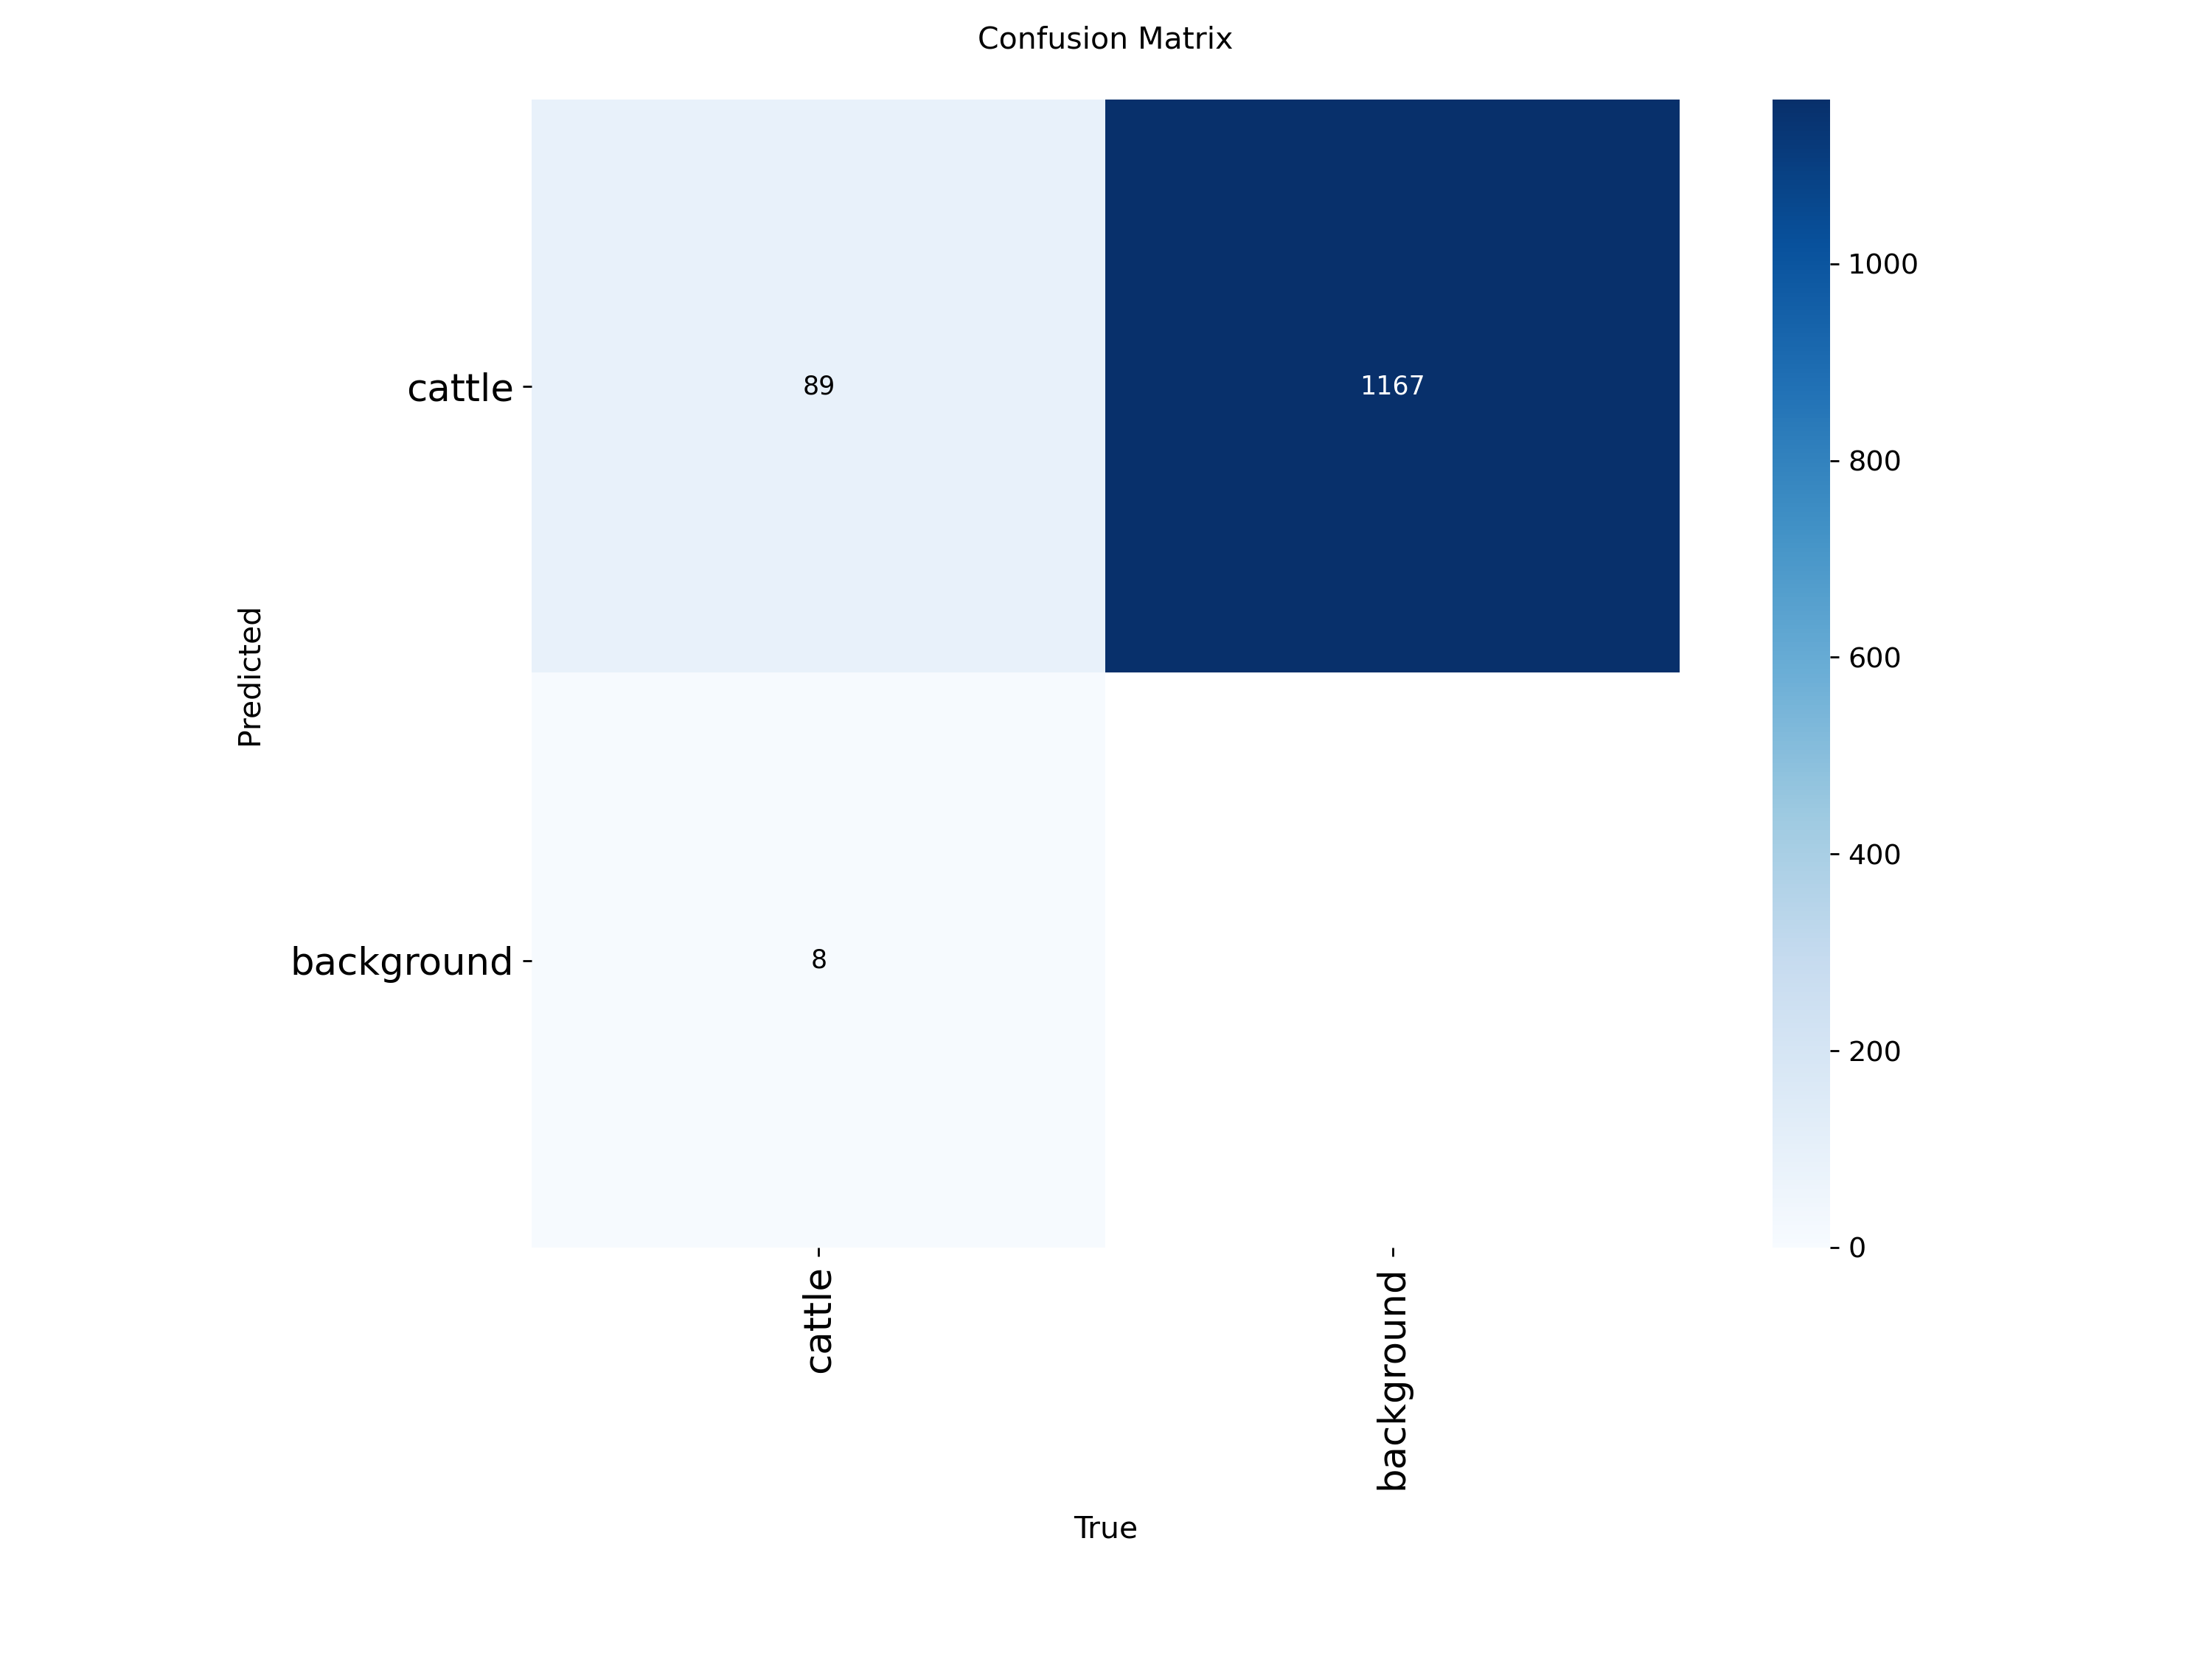

--- confusion_matrix_normalized.png ---


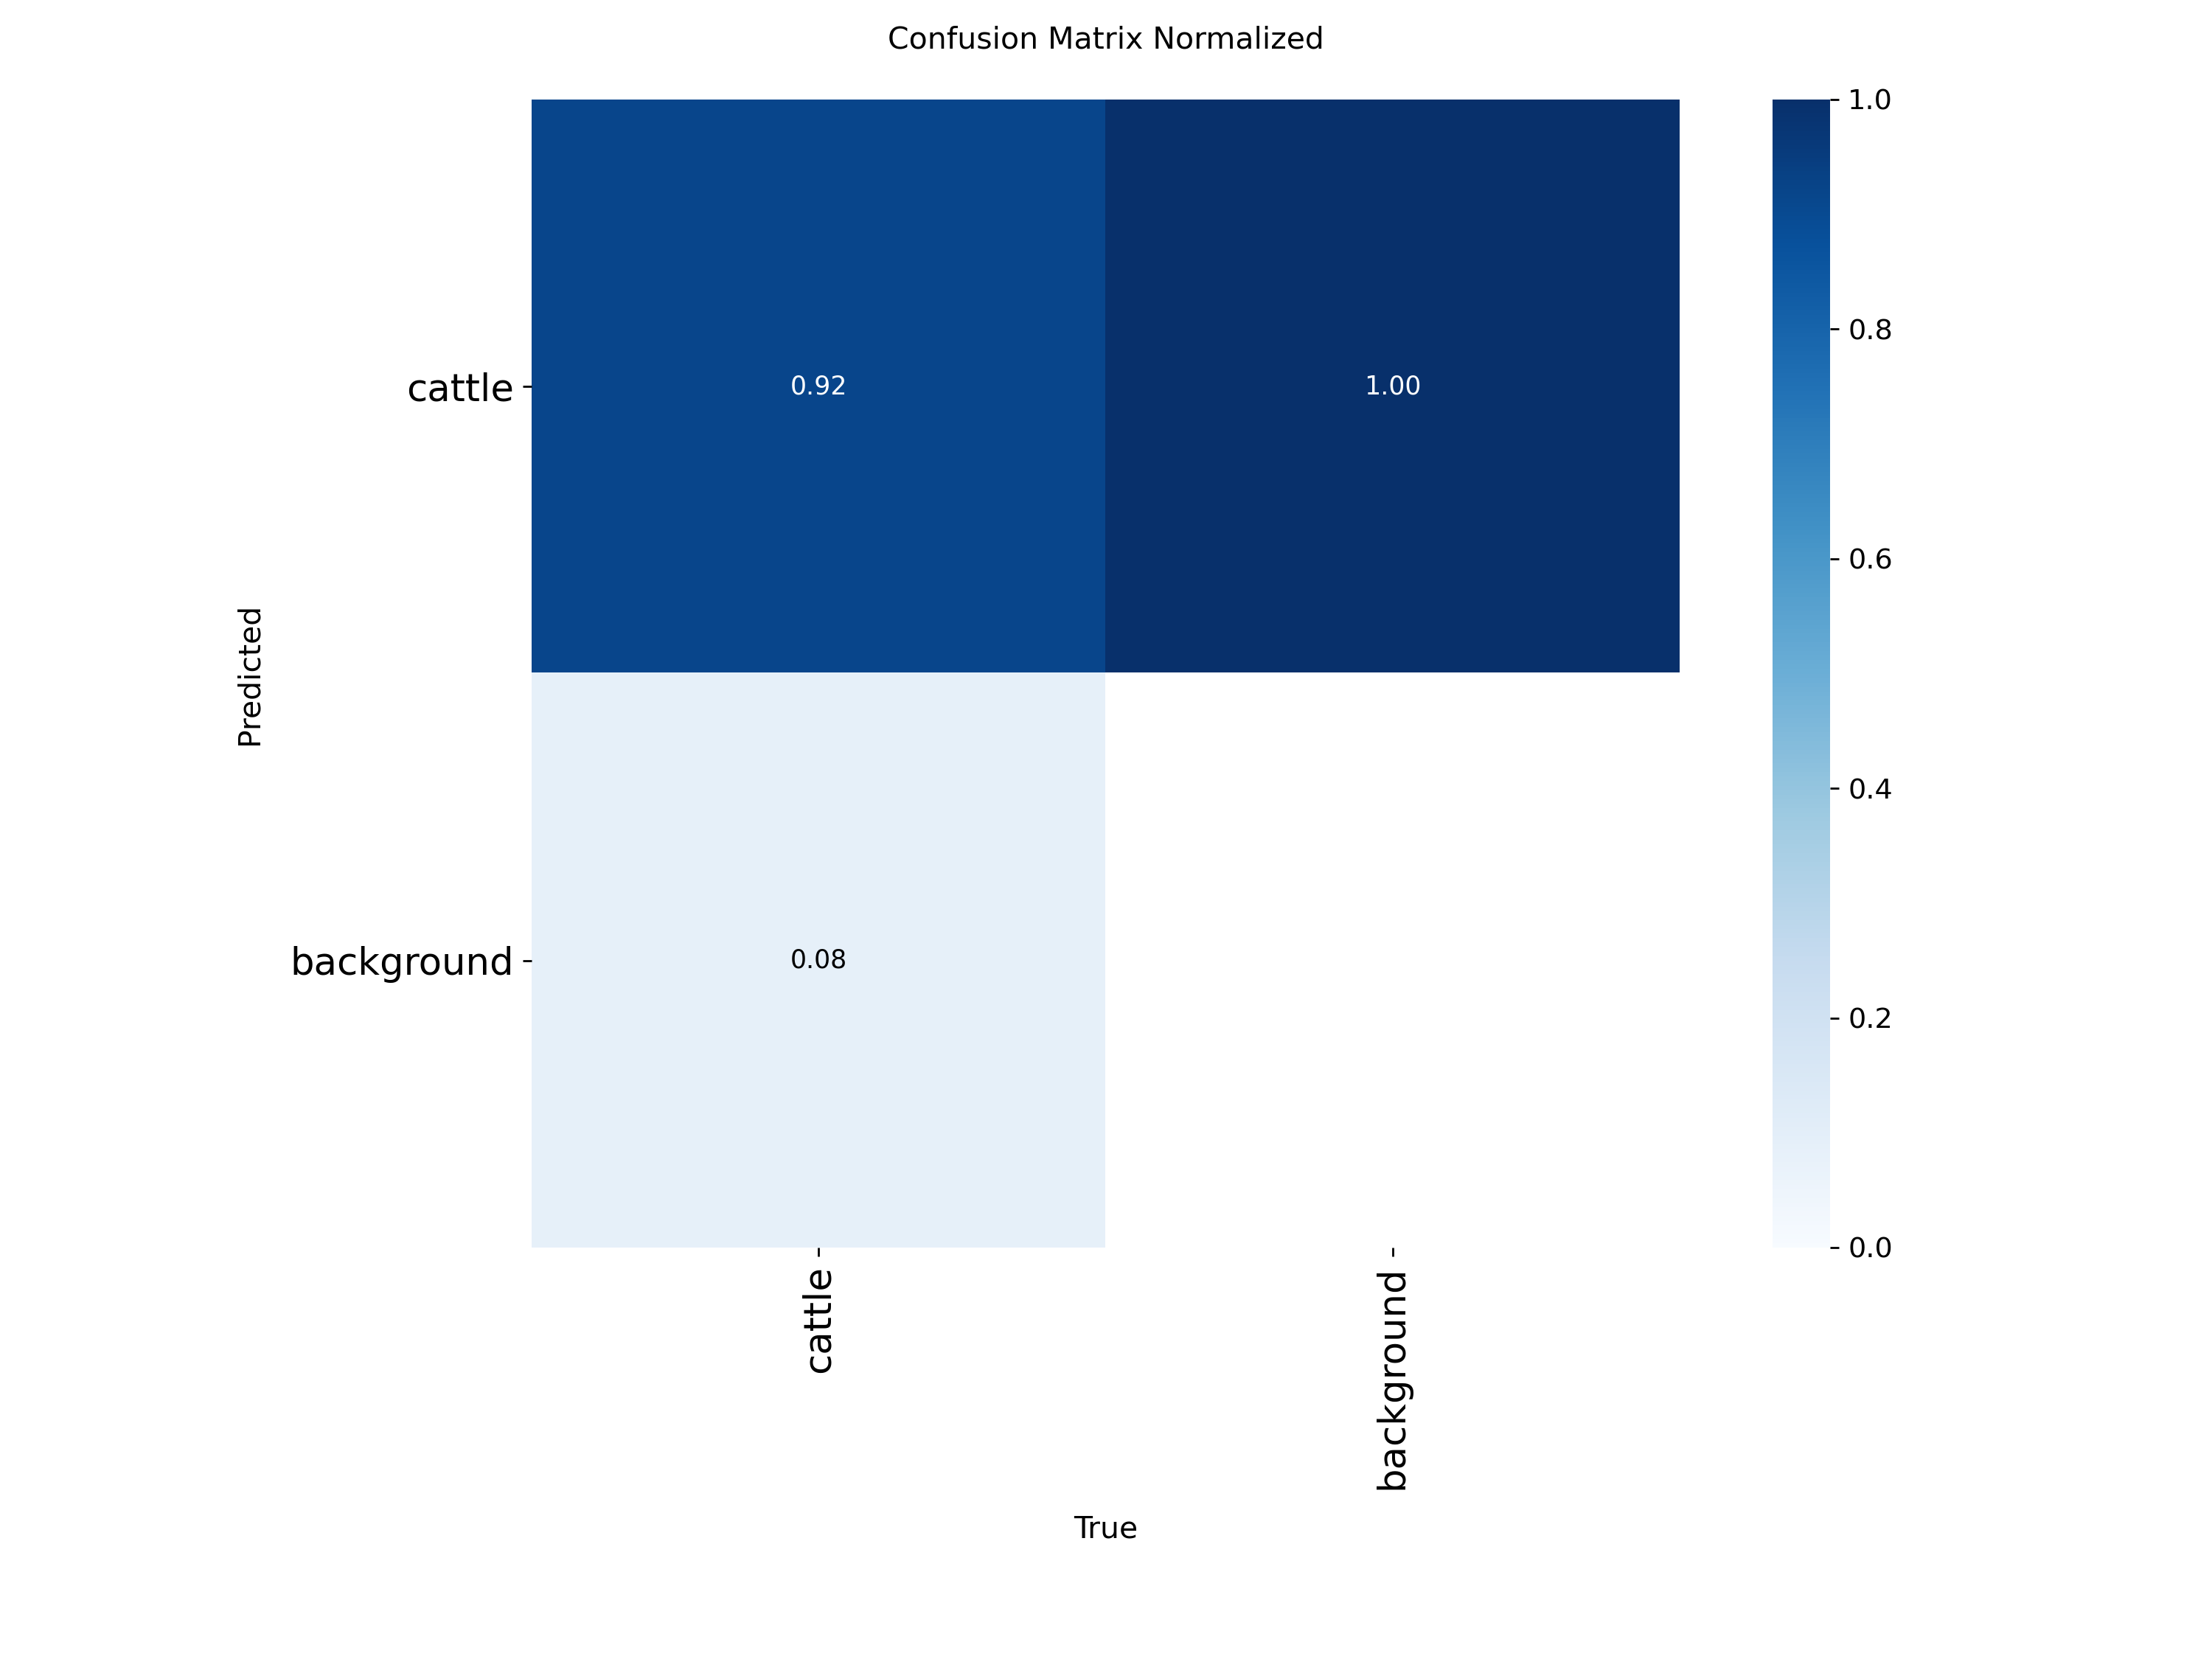

--- BoxPR_curve.png ---


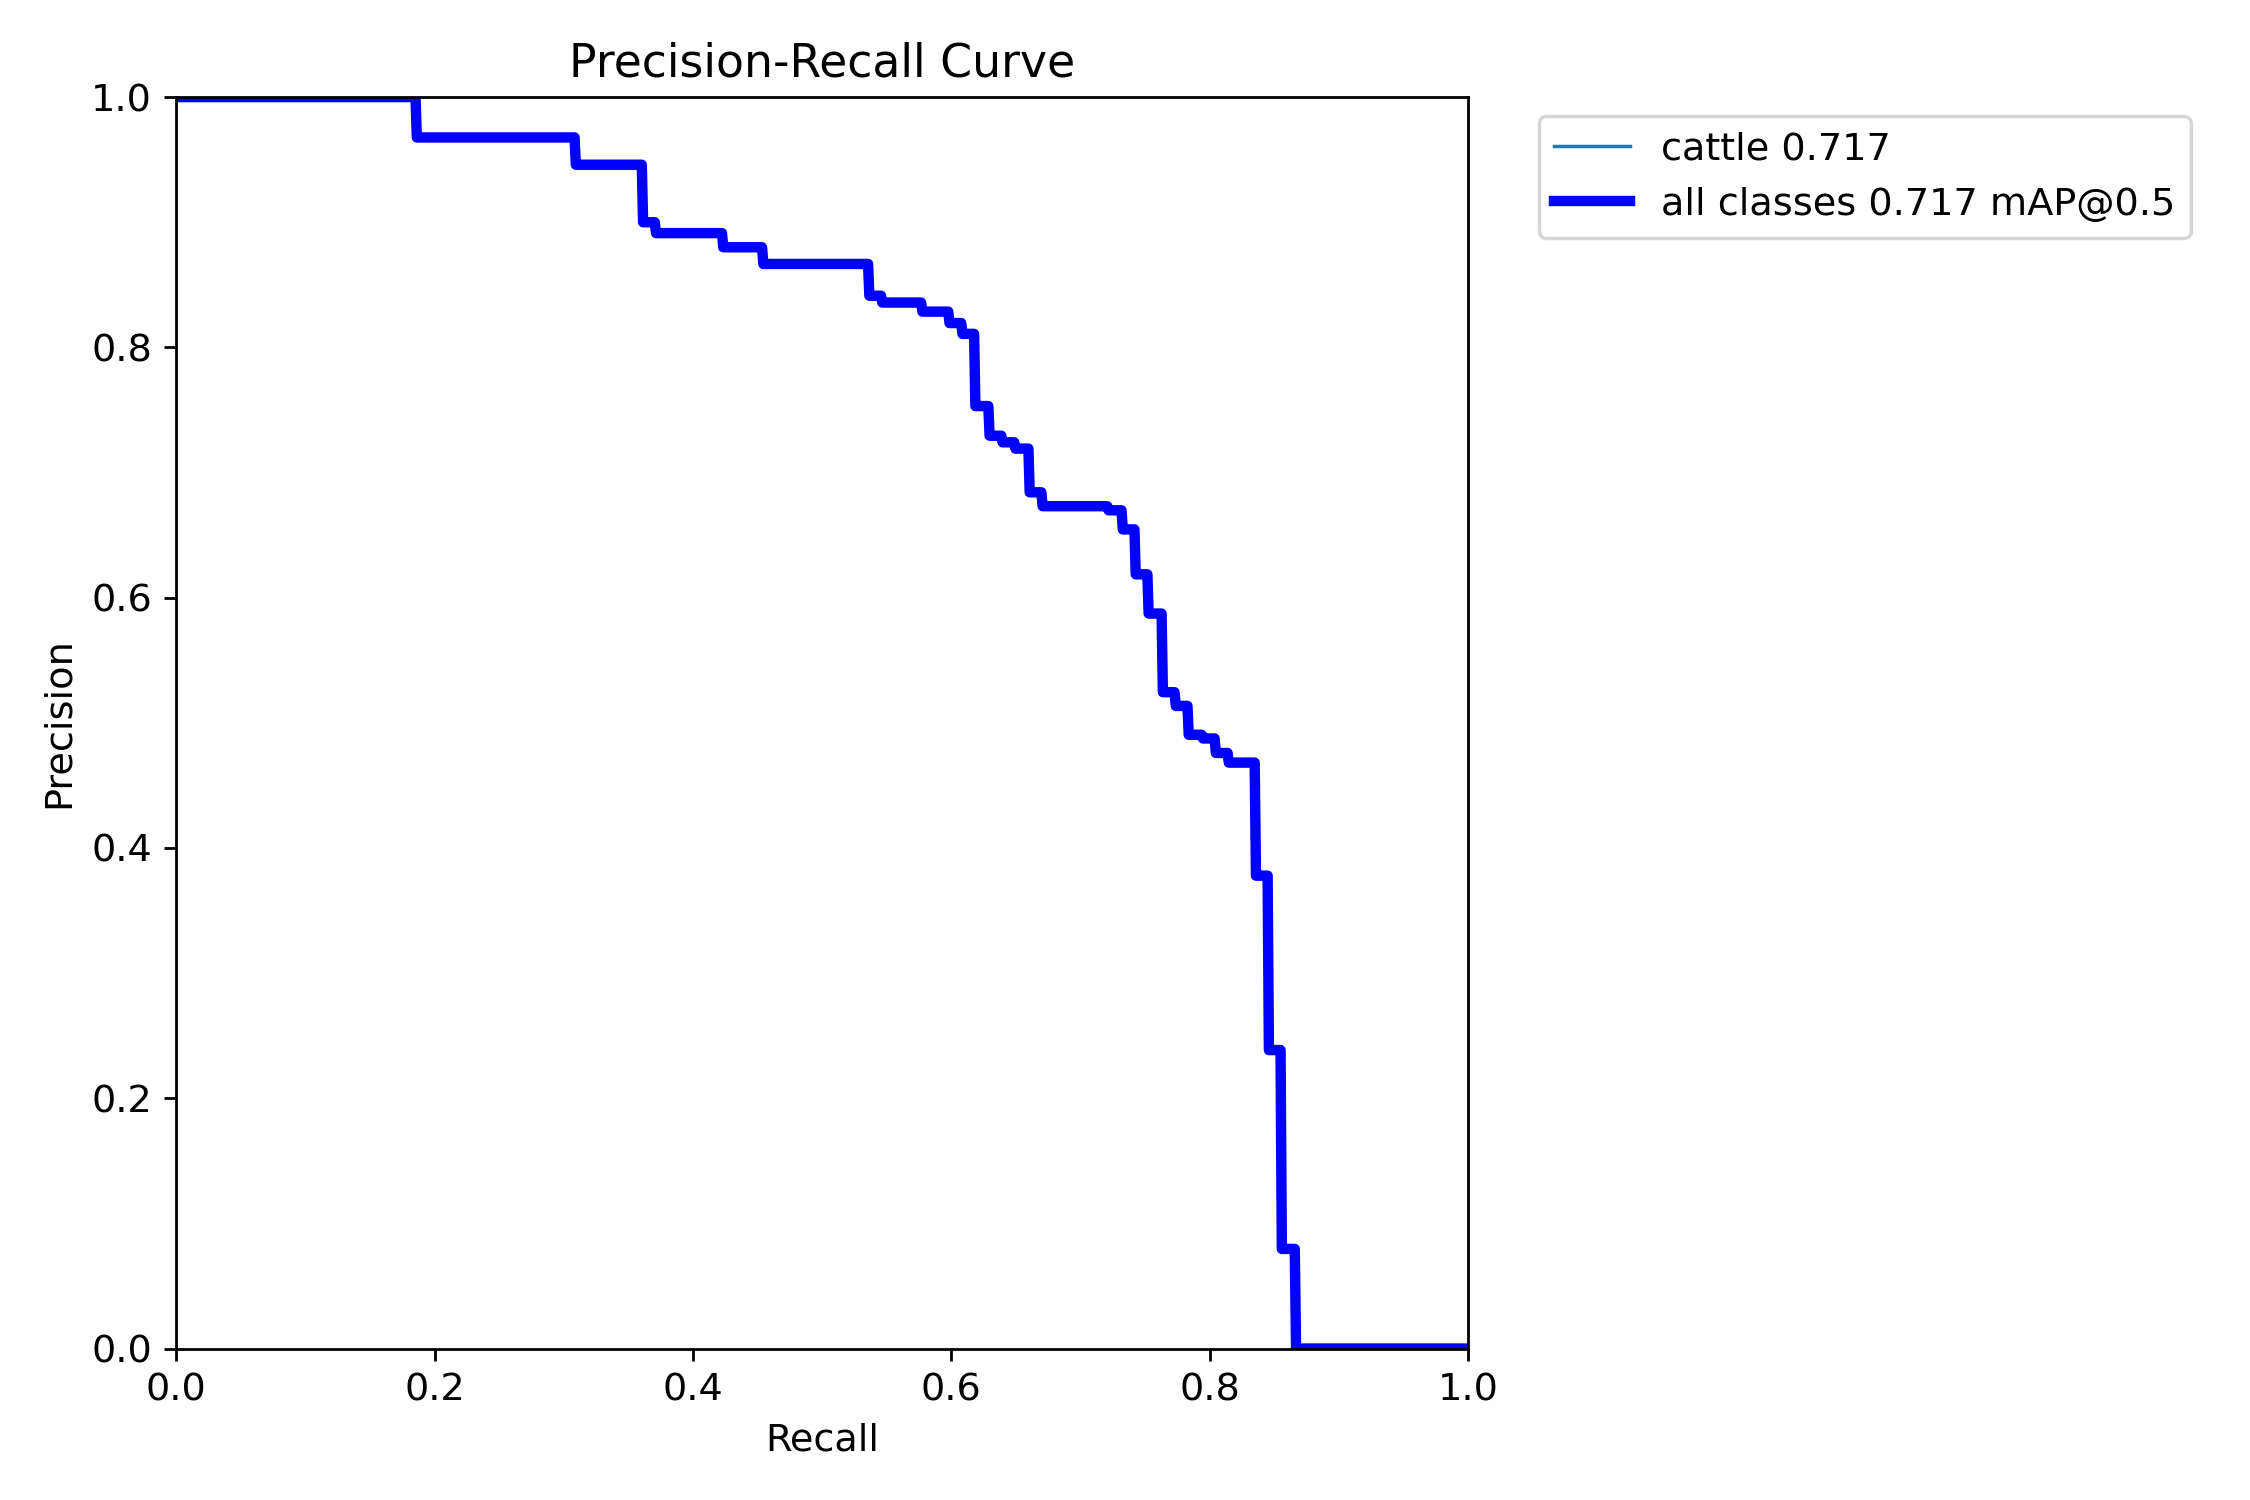

--- BoxF1_curve.png ---


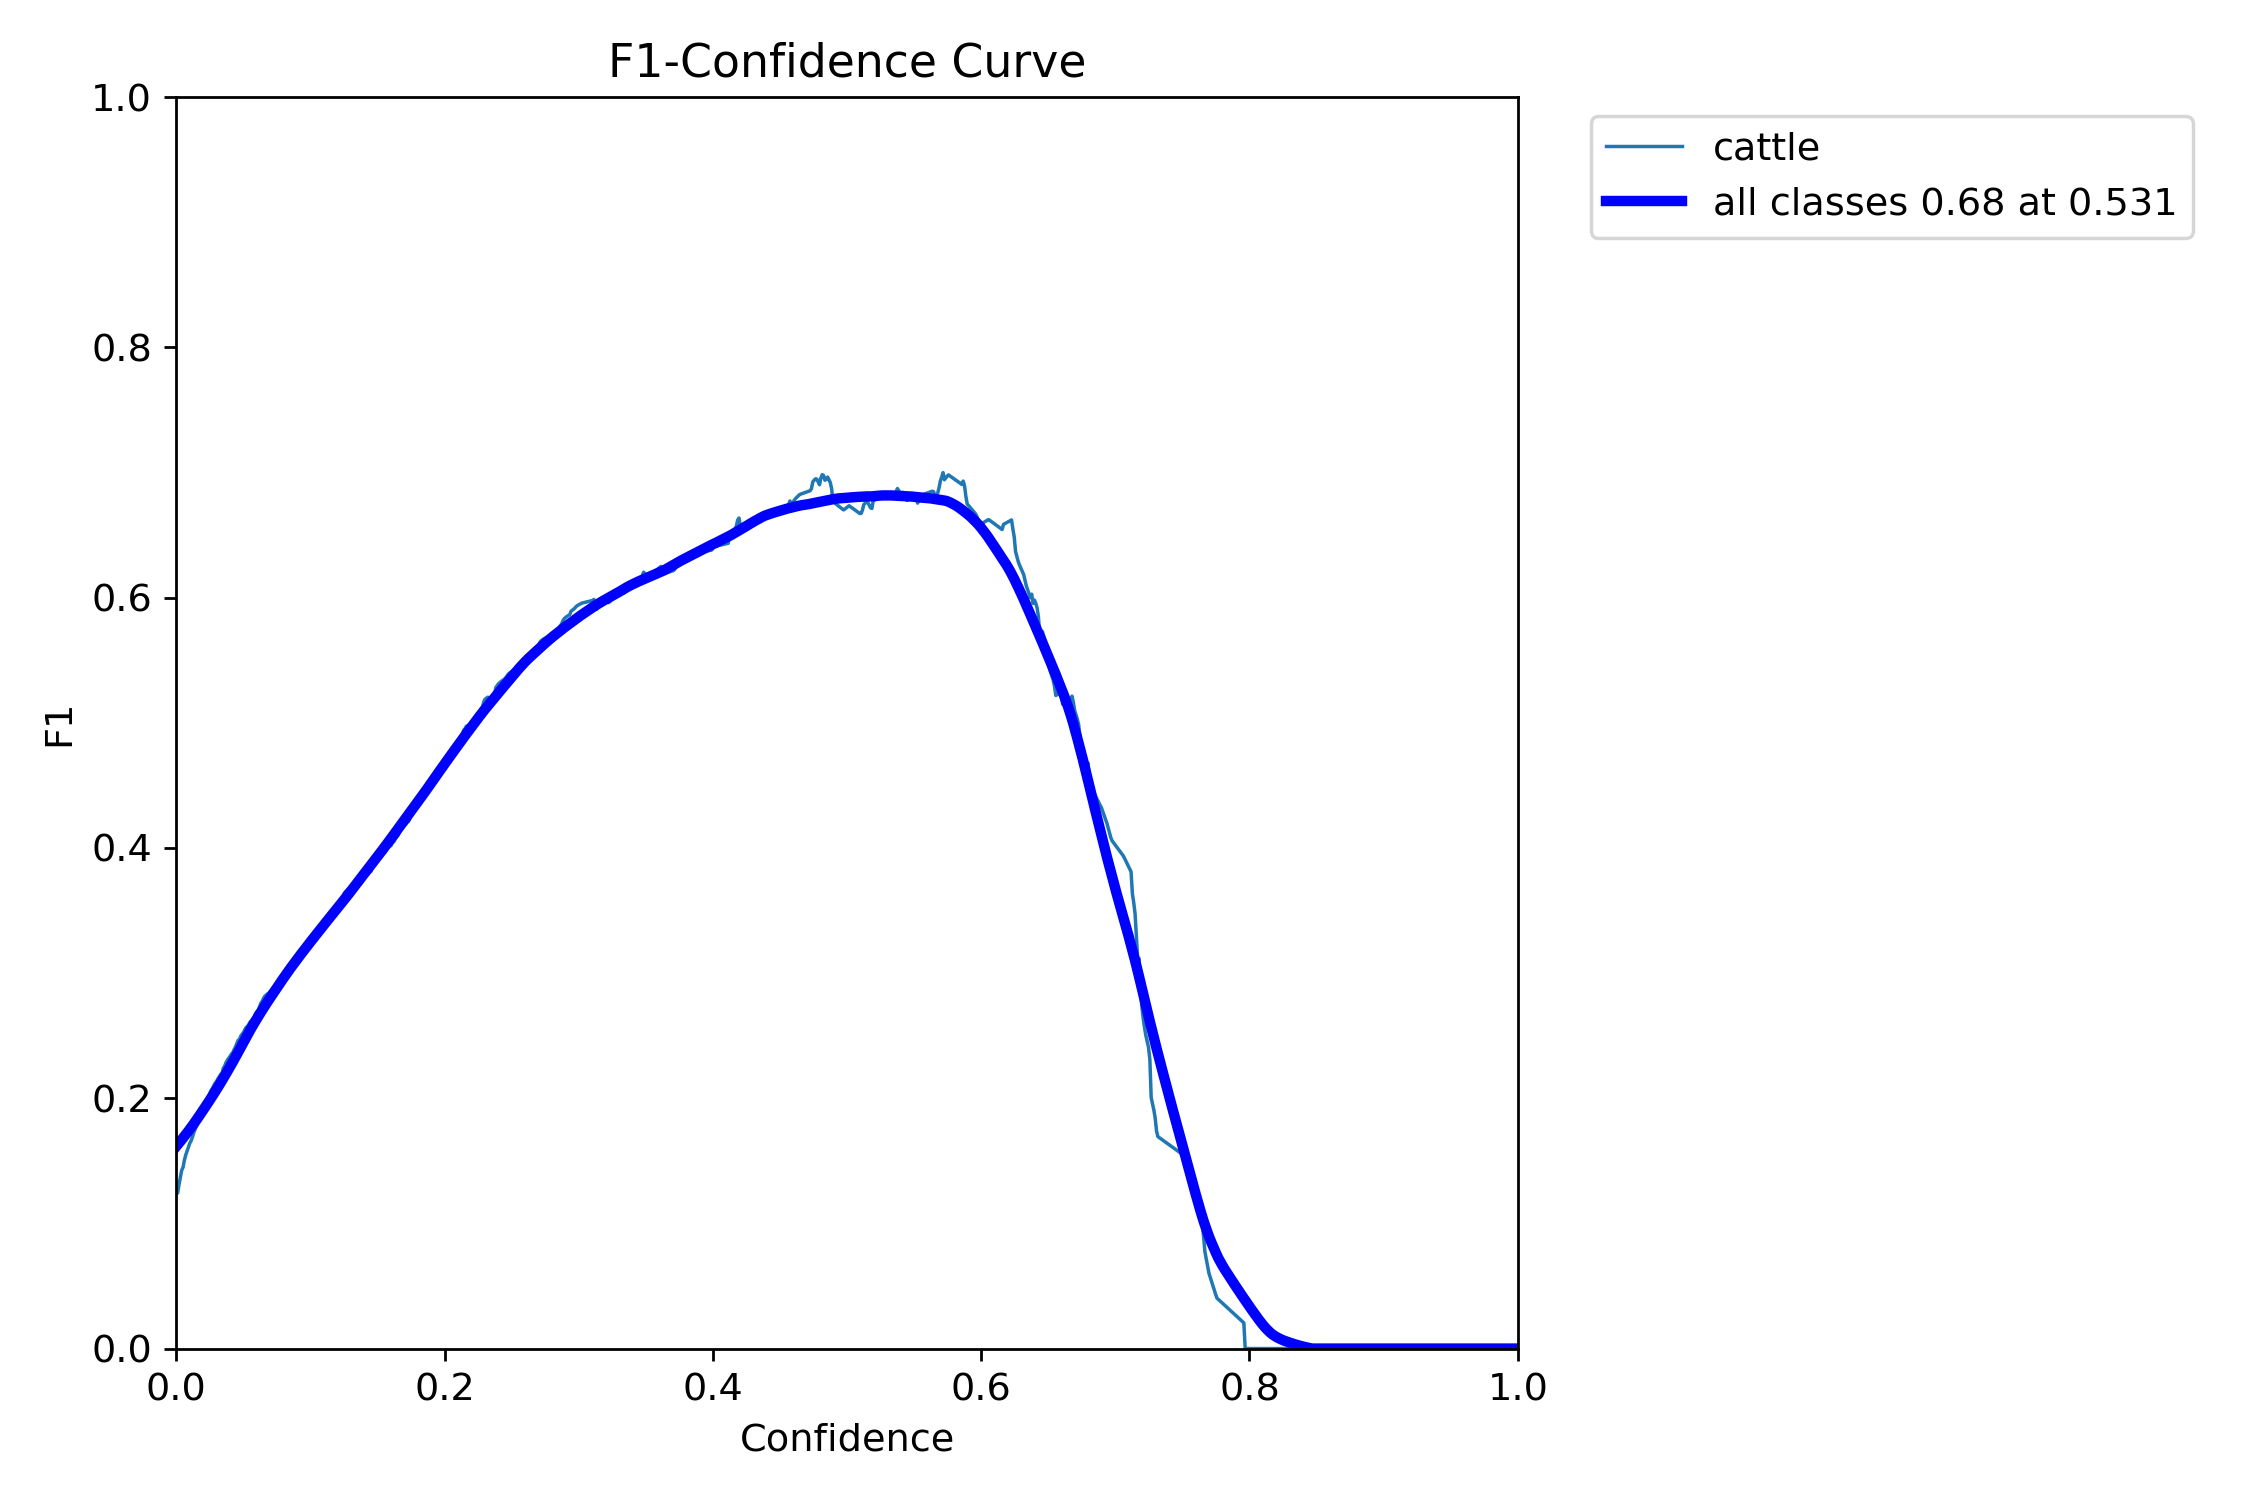

--- BoxP_curve.png ---


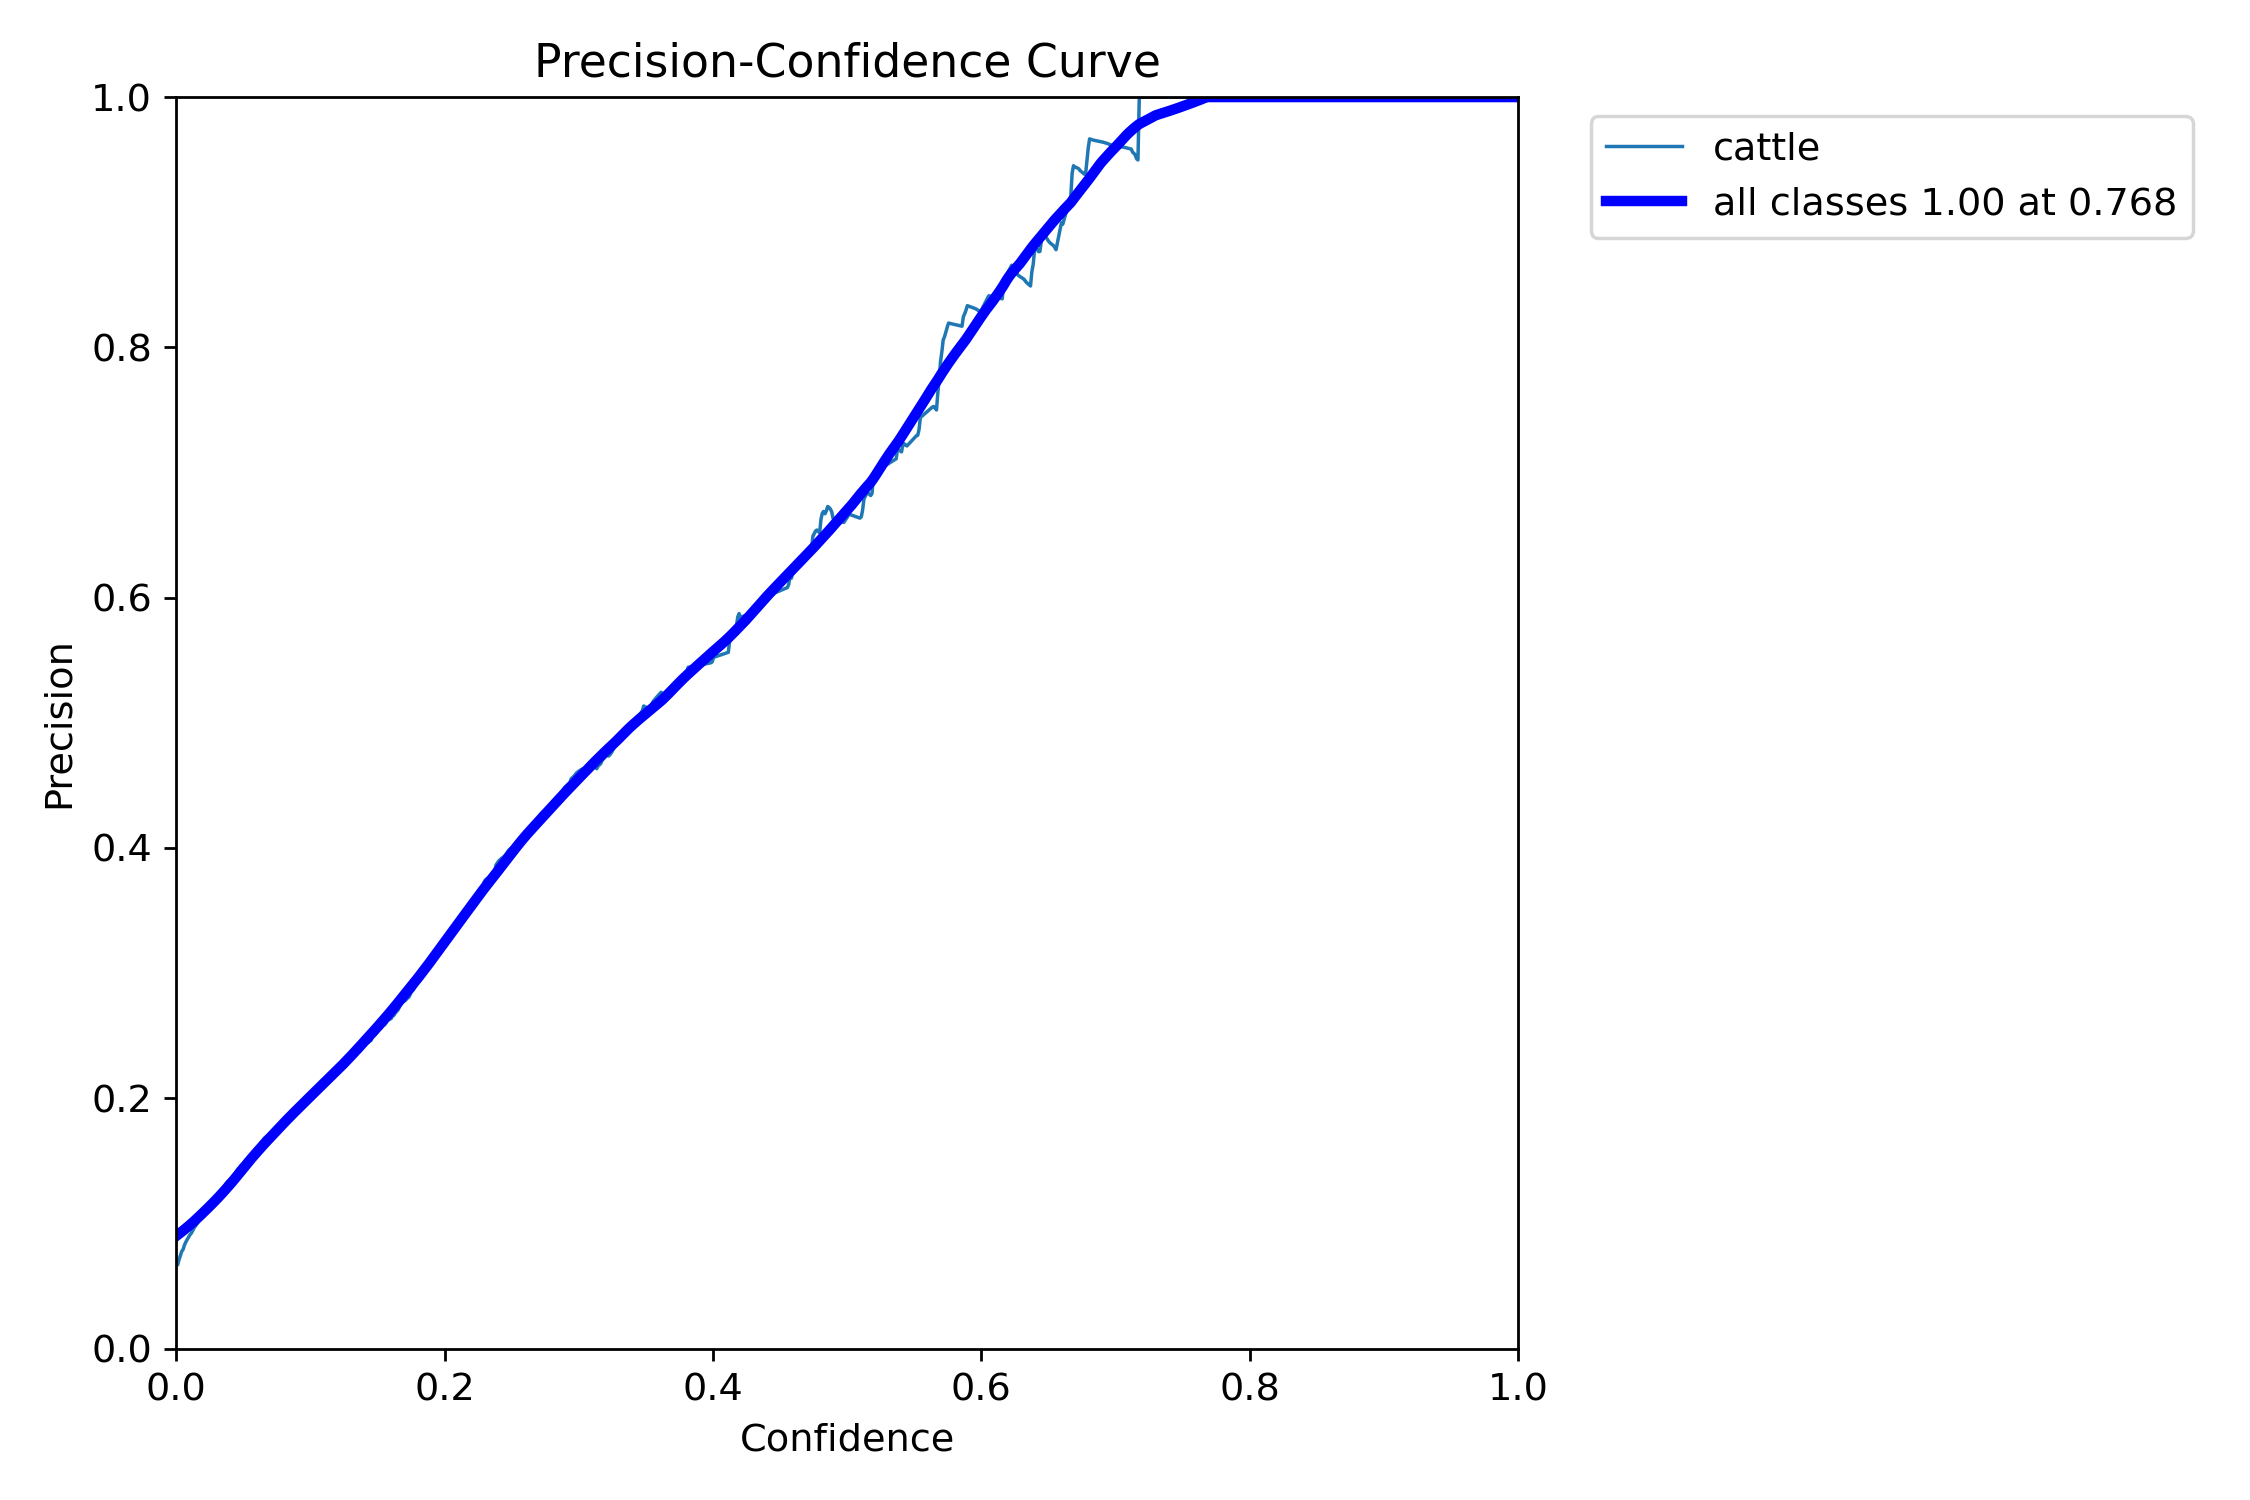

--- BoxR_curve.png ---


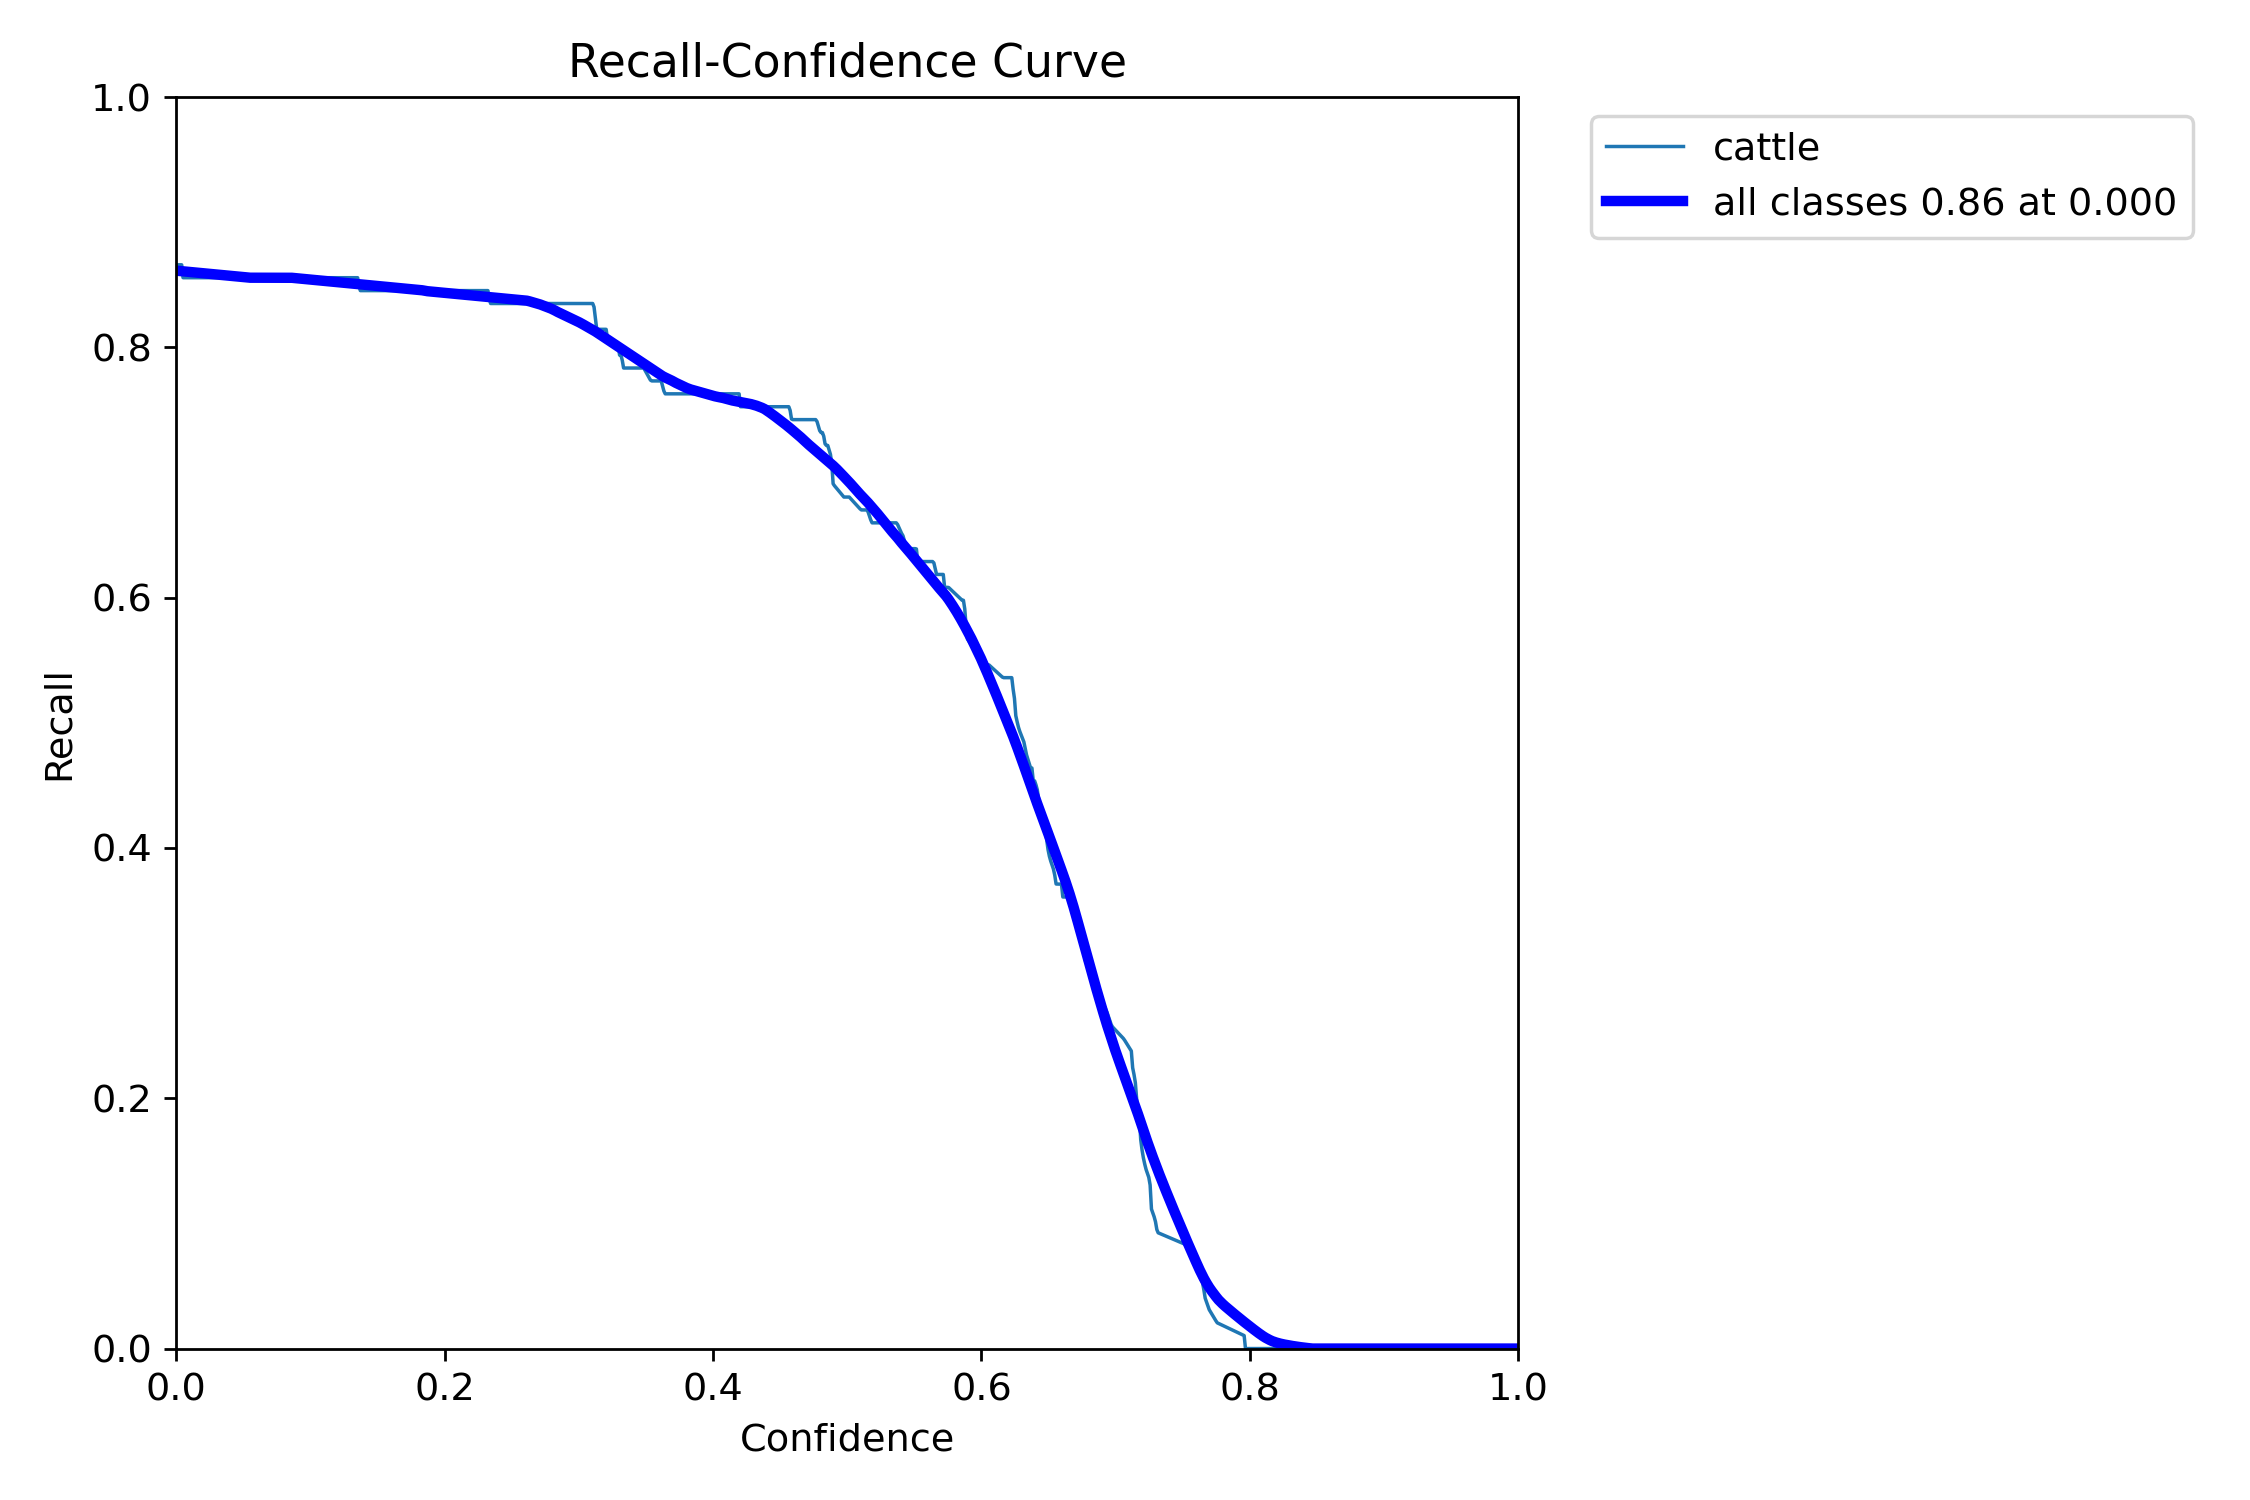

In [38]:
import os
from IPython.display import Image, display

# 1. Print the evaluation numbers clearly
print(f"=== Fine-Tuned Model Validation Metrics ===")
print(f"mAP50: {metrics.box.map50:.4f}")
print(f"mAP50-95: {metrics.box.map:.4f}")
print(f"Precision: {metrics.box.p.mean():.4f}")
print(f"Recall: {metrics.box.r.mean():.4f}\n")

# 2. Path where validation results were saved
val_dir = '/content/runs/detect/val-2'

# List of common graphs generated during validation
plots = [
    'confusion_matrix.png',
    'confusion_matrix_normalized.png',
    'BoxPR_curve.png',
    'BoxF1_curve.png',
    'BoxP_curve.png',
    'BoxR_curve.png'
]

# 3. Display each graph sequentially
for plot in plots:
    plot_path = os.path.join(val_dir, plot)
    if os.path.exists(plot_path):
        print(f"--- {plot} ---")
        display(Image(filename=plot_path, width=600))
    else:
        print(f"Plot not found: {plot}")